In [1]:
# from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
import seaborn as sns
# from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os
# from brokenaxes import brokenaxes

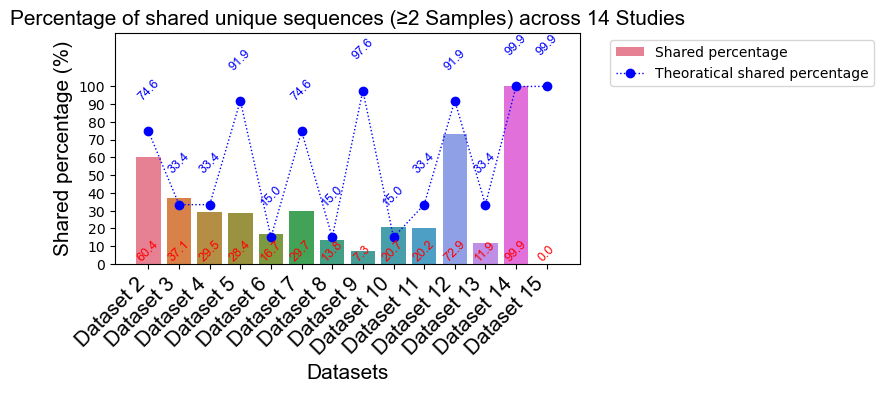

In [2]:


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


data = pd.DataFrame({
    'mapping_type' : ["Dataset 2", "Dataset 3", "Dataset 4", "Dataset 5", "Dataset 6","Dataset 7","Dataset 8","Dataset 9","Dataset 10",
                        "Dataset 11","Dataset 12","Dataset 13", "Dataset 14", "Dataset 15"],
    'percentages': [60.37, 37.09, 29.50, 28.44, 16.67, 29.74, 13.75, 7.29, 20.67, 20.21, 72.92, 11.93, 99.94, 0],  
    'Sample' : ["dataset 2", "dataset 3", "dataset 4", "dataset 5", "dataset 6","dataset 7","dataset 8","dataset 9","dataset 10",
                        "dataset 11","dataset 12","dataset 13", "dataset 14", "dataset 15"],
    'baseline' :    [74.64, 33.38, 33.38, 91.86, 15, 74.64, 15, 97.60, 15, 33.38, 91.86, 33.38, 99.88, 99.92 ]
    })

#[6,3,3,9,2,6,2,12,2,3,9,3,18,20]

# palette = {
#     "SRR18078867": "red",   # blue
#     "SRR18078868": "orange",   # red
#     "SRR18078869": "blue",    # green
#     "SRR18078870": "green",     # gold
#     "SRR18078871": "pink",     # gold
#     "SRR18078872": "gray"     # gold
# }
fig, ax = plt.subplots(figsize=(6,3))
# bars = ax.bar(x, percentages, color=["red","orange","blue","green","pink","gray"])    
barplot = sns.barplot(
    data=data,
    x="mapping_type",
    y="percentages",
    hue='Sample',
    ax=ax
)
for i, row in data.iterrows():
    ax.text(
        i,  0,
        f"{row['percentages']:.1f}",
        ha='center', va='bottom', rotation=45,color="red",
        fontproperties=arial_font_in
    )

#lineplot
lineplot, = ax.plot(
    data["mapping_type"],
    data["baseline"],
    color="blue",
    marker="o",
    linewidth=1,
    linestyle=":",
    label="baseline (same scale)"
)

# 
for i, row in data.iterrows():
     ax.text(
        i, row["baseline"]+16,
        f"{row['baseline']:.1f}",
        ha='center', va='bottom', rotation=45, color="blue",
        fontproperties=arial_font_in
    )
bar_patch = barplot.patches[0]  # first bar from first hue group
custom_handles = [bar_patch, lineplot]
custom_labels = ["Shared percentage", "Theoratical shared percentage"]

ax.legend(custom_handles, custom_labels, loc="upper left", bbox_to_anchor=(1.05, 1.0))
# for label in ax.get_xticklabels() + ax.get_yticklabels():
#     label.set_fontproperties(arial_font)
ax.set_xlabel('Datasets', fontproperties=arial_font)
ax.set_ylabel('Shared percentage (%)',fontproperties=arial_font)
ax.set_title('Percentage of shared unique sequences (≥2 Samples) across 14 Studies' ,fontproperties=arial_font)
# ax.set_ylim(0, 100)
ax.margins(x=0.05)
ax.set_ylim(0, 130)           # visually extend to 105
ax.set_yticks(range(0, 101, 10))
# ax.legend().set_visible(False)
plt.xticks(rotation=45, ha='right', fontproperties=arial_font)

plt.savefig("supp_figure5_percentage.pdf", format="pdf", bbox_inches="tight")




0     5.912324
1     6.950994
2     6.153136
3     6.996804
4     5.427981
5     6.970424
6     5.938625
7     6.303157
8     5.629712
9     4.823943
10    4.062883
11    3.930083
12    8.700272
13    8.700272
Name: log_total, dtype: float64


/tmp/ipykernel_3644543/1427618491.py:102: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax.set_ylim(0, 12)


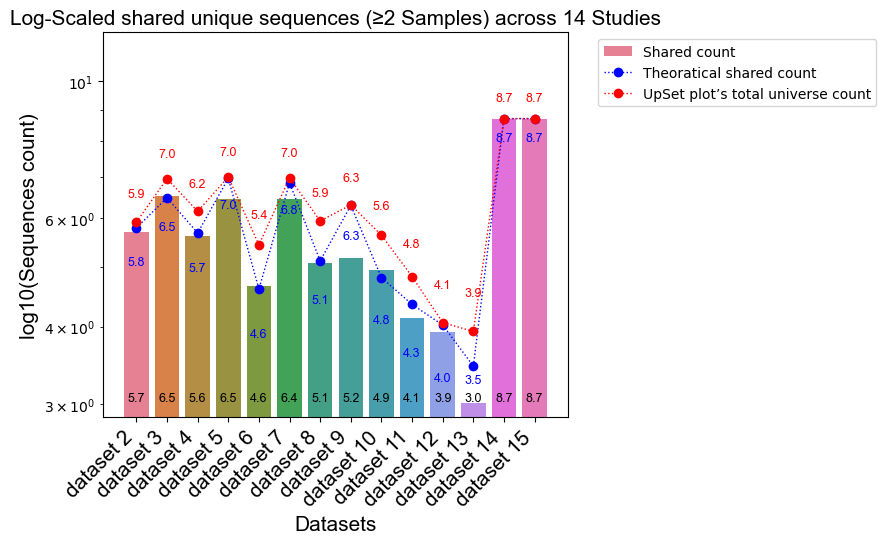

In [3]:


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


data = pd.DataFrame({
'mapping_type' : ["dataset 2", "dataset 3", "dataset 4", "dataset 5", "dataset 6","dataset 7","dataset 8","dataset 9","dataset 10",
                    "dataset 11","dataset 12","dataset 13", "dataset 14", "dataset 15"],
'counts': [493353, 3313266,419776,2822734,44667,2778121,119362,146437,88095,13474,8428,1016,501221851,501221851],  
'Sample' : ["dataset 2", "dataset 3", "dataset 4", "dataset 5", "dataset 6","dataset 7","dataset 8","dataset 9","dataset 10",
                    "dataset 11","dataset 12","dataset 13", "dataset 14", "dataset 15"],
'baseline': [817191*0.7464, 8932941*0.3338,1422775*0.3338, 9926685*0.9186, 267905*0.15, 9341663*0.7464, 868210*0.15, 2009821*0.976, 426297*0.15, 66672*0.3338, 11558*0.9186,8513*0.3338, 501501133*0.9988,501501133*0.9992],
'total' : [817191, 8932941, 1422775, 9926685, 267905, 9341663, 868210, 2009821, 426297, 66672, 11558, 8513, 501501133,501501133]
})
data["log_counts"] = np.log10(data["counts"])
data["log_baseline"] = np.log10(data["baseline"])
data["log_total"] = np.log10(data["total"])
print(data["log_total"])
# print(data["log_counts"])
# print(data["log_baseline"])
fig, ax = plt.subplots(figsize=(6,5))

# bars = ax.bar(x, counts, color=["red","orange","blue","green","pink","gray"])    
barplot = sns.barplot(
    data=data,
    x="mapping_type",
    y="log_counts",
    hue='Sample',
    ax=ax
)
for i, row in data.iterrows():
    ax.text(
        i, 3,
        f"{row['log_counts']:.1f}",
        ha='center', va='bottom', 
        fontproperties=arial_font_in
    )
#lineplot
lineplot, = ax.plot(
    data["mapping_type"],
    data["log_baseline"],
    color="blue",
    marker="o",
    linewidth=1,
    linestyle=":",
    label="baseline (same scale)"
)

# 
for i, row in data.iterrows():
    if i == 11:
       ax.text(
        i,3.2,
        f"{row['log_baseline']:.1f}",
        ha='center', va='bottom', color="blue",
        fontproperties=arial_font_in
    )
    else: 
        ax.text(
        i, row['log_baseline']-0.8,
        f"{row['log_baseline']:.1f}",
        ha='center', va='bottom', color="blue",
        fontproperties=arial_font_in
    )


line2plot, = ax.plot(
    data["mapping_type"],
    data["log_total"],
    color="red",
    marker="o",
    linewidth=1,
    linestyle=":",
    label="baseline (same scale)"
)

# 
for i, row in data.iterrows():
     ax.text(
        i, row['log_total']+0.5,
        f"{row['log_total']:.1f}",
        ha='center', va='bottom', color="red",
        fontproperties=arial_font_in
    )

ax.set_yscale("log")

bar_patch = ax.patches[0]
ax.legend(
    [bar_patch, lineplot, line2plot],
    ["Shared count", "Theoratical shared count", "UpSet plot’s total universe count"],
    loc="upper left",
    bbox_to_anchor=(1.05, 1.0)
)
ax.set_xlabel('Datasets', fontproperties=arial_font)
ax.set_ylabel('log10(Sequences count)',fontproperties=arial_font)
# for label in ax.get_xticklabels() + ax.get_yticklabels():
#     label.set_fontproperties(arial_font)
ax.set_title('Log-Scaled shared unique sequences (≥2 Samples) across 14 Studies' ,fontproperties=arial_font)
ax.set_ylim(0, 12)
ax.margins(x=0.05)
# ax.set_ylim(0, 120)           # visually extend to 105
# ax.set_yticks(range(0, 100, 1))

plt.xticks(rotation=45, ha='right', fontproperties=arial_font)

plt.savefig("supp_figure5_counts.pdf", format="pdf", bbox_inches="tight")




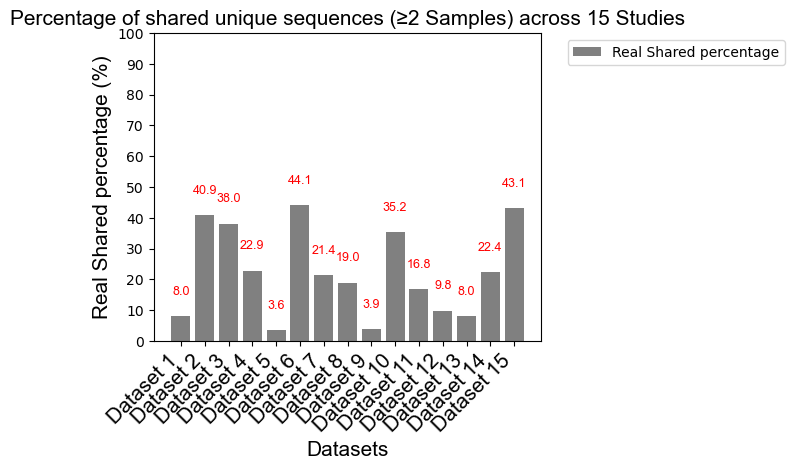

In [4]:


fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=15)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=9)


data = pd.DataFrame({
    'mapping_type' : ["Dataset 1","Dataset 2", "Dataset 3", "Dataset 4", "Dataset 5", "Dataset 6","Dataset 7","Dataset 8","Dataset 9","Dataset 10",
                        "Dataset 11","Dataset 12","Dataset 13", "Dataset 14", "Dataset 15"],
    'percentages': [8.01, 40.86, 38.03, 22.86, 3.58, 44.09, 21.43, 18.96, 3.89, 35.22, 16.79, 9.80, 8.02, 22.40, 43.15],  
    'Sample' : ["dataset 1","dataset 2", "dataset 3", "dataset 4", "dataset 5", "dataset 6","dataset 7","dataset 8","dataset 9","dataset 10",
                        "dataset 11","dataset 12","dataset 13", "dataset 14", "dataset 15"]
    # 'baseline' :    [74.64, 33.38, 33.38, 91.86, 15, 74.64, 15, 97.60, 15, 33.38, 91.86, 33.38, 99.88, 99.92 ]
    })

#[6,3,3,9,2,6,2,12,2,3,9,3,18,20]
# colors = [plt.cm.Reds(i) for i in np.linspace(0.2, 1, 14)] 
colors = ['#3b4cc0', '#516cc4', '#668cc8', '#7baccc', '#8ec9ce', '#a1e0ce',
 '#c0e6b2', '#e0db8a', '#f4c264', '#f69b4a', '#ef6f34', '#e24326',
 '#ca1a1a', '#b40426']
# palette = {
#     "SRR18078867": "red",   # blue
#     "SRR18078868": "orange",   # red
#     "SRR18078869": "blue",    # green
#     "SRR18078870": "green",     # gold
#     "SRR18078871": "pink",     # gold
#     "SRR18078872": "gray"     # gold
# }
fig, ax = plt.subplots(figsize=(5,4))
# bars = ax.bar(x, percentages, color=["red","orange","blue","green","pink","gray"])    
barplot = sns.barplot(
    data=data,
    x="mapping_type",
    y="percentages",
    # hue='Sample',
    ax=ax
)
for i, bar in enumerate(barplot.patches):
    bar.set_facecolor("gray")

for i, row in data.iterrows():
    ax.text(
        i, row["percentages"]+10,
        f"{row['percentages']:.1f}",
        ha='center', va='top', color="red",
        fontproperties=arial_font_in
    )

# #lineplot
# lineplot, = ax.plot(
#     data["mapping_type"],
#     color="blue",
#     marker="o",
#     linewidth=1,
#     linestyle=":",
#     label="baseline (same scale)"
# )

# 
# for i, row in data.iterrows():
#      ax.text(
#         i, row["baseline"]+16,
#         f"{row['baseline']:.1f}",
#         ha='center', va='bottom', rotation=45, color="blue",
#         fontproperties=arial_font_in
#     )
bar_patch = barplot.patches[0]  # first bar from first hue group
custom_handles = [bar_patch]
custom_labels = ["Real Shared percentage"]

ax.legend(custom_handles, custom_labels, loc="upper left", bbox_to_anchor=(1.05, 1.0))
# for label in ax.get_xticklabels() + ax.get_yticklabels():
#     label.set_fontproperties(arial_font)
ax.set_xlabel('Datasets', fontproperties=arial_font)
ax.set_ylabel('Real Shared percentage (%)',fontproperties=arial_font)
ax.set_title('Percentage of shared unique sequences (≥2 Samples) across 15 Studies' ,fontproperties=arial_font)
# ax.set_ylim(0, 100)
ax.margins(x=0.05)
ax.set_ylim(0, 100)           # visually extend to 105
ax.set_yticks(range(0, 101, 10))
# ax.legend().set_visible(False)
plt.xticks(rotation=45, ha='right', fontproperties=arial_font)

plt.savefig("figure7_0.pdf", format="pdf", bbox_inches="tight")


[0.0, 27.089999999999996, 47.14, 62.28, 73.35000000000001, 81.71000000000001, 87.91, 92.43, 95.6, 97.7, 98.97, 99.63, 99.9, 99.97, 99.99, 99.997, 99.99900000000001, 99.9995, 99.99980000000001, 99.9999]
        x        y  size    total  categorical_variable
11   9.80  95.6000     9     2550                    12
12   8.02  47.1400     3     6795                    13
10  16.79  47.1400     3    43804                    11
13  22.40  99.9995    18   140193                    14
1   40.86  81.7100     6   186577                     2
9   35.22  27.0900     2   250107                    10
7   18.96  27.0900     2   629486                     8
3   22.86  47.1400     3   748943                     4
5   44.09  92.4300     8  1154904                     6
8    3.89  98.9700    11  1392991                     9
0    8.01  98.9700    11  1520705                     1
6   21.43  47.1400     3  1759510                     7
14  43.15  99.9999    20  3577286                    15
2   38.03  47.

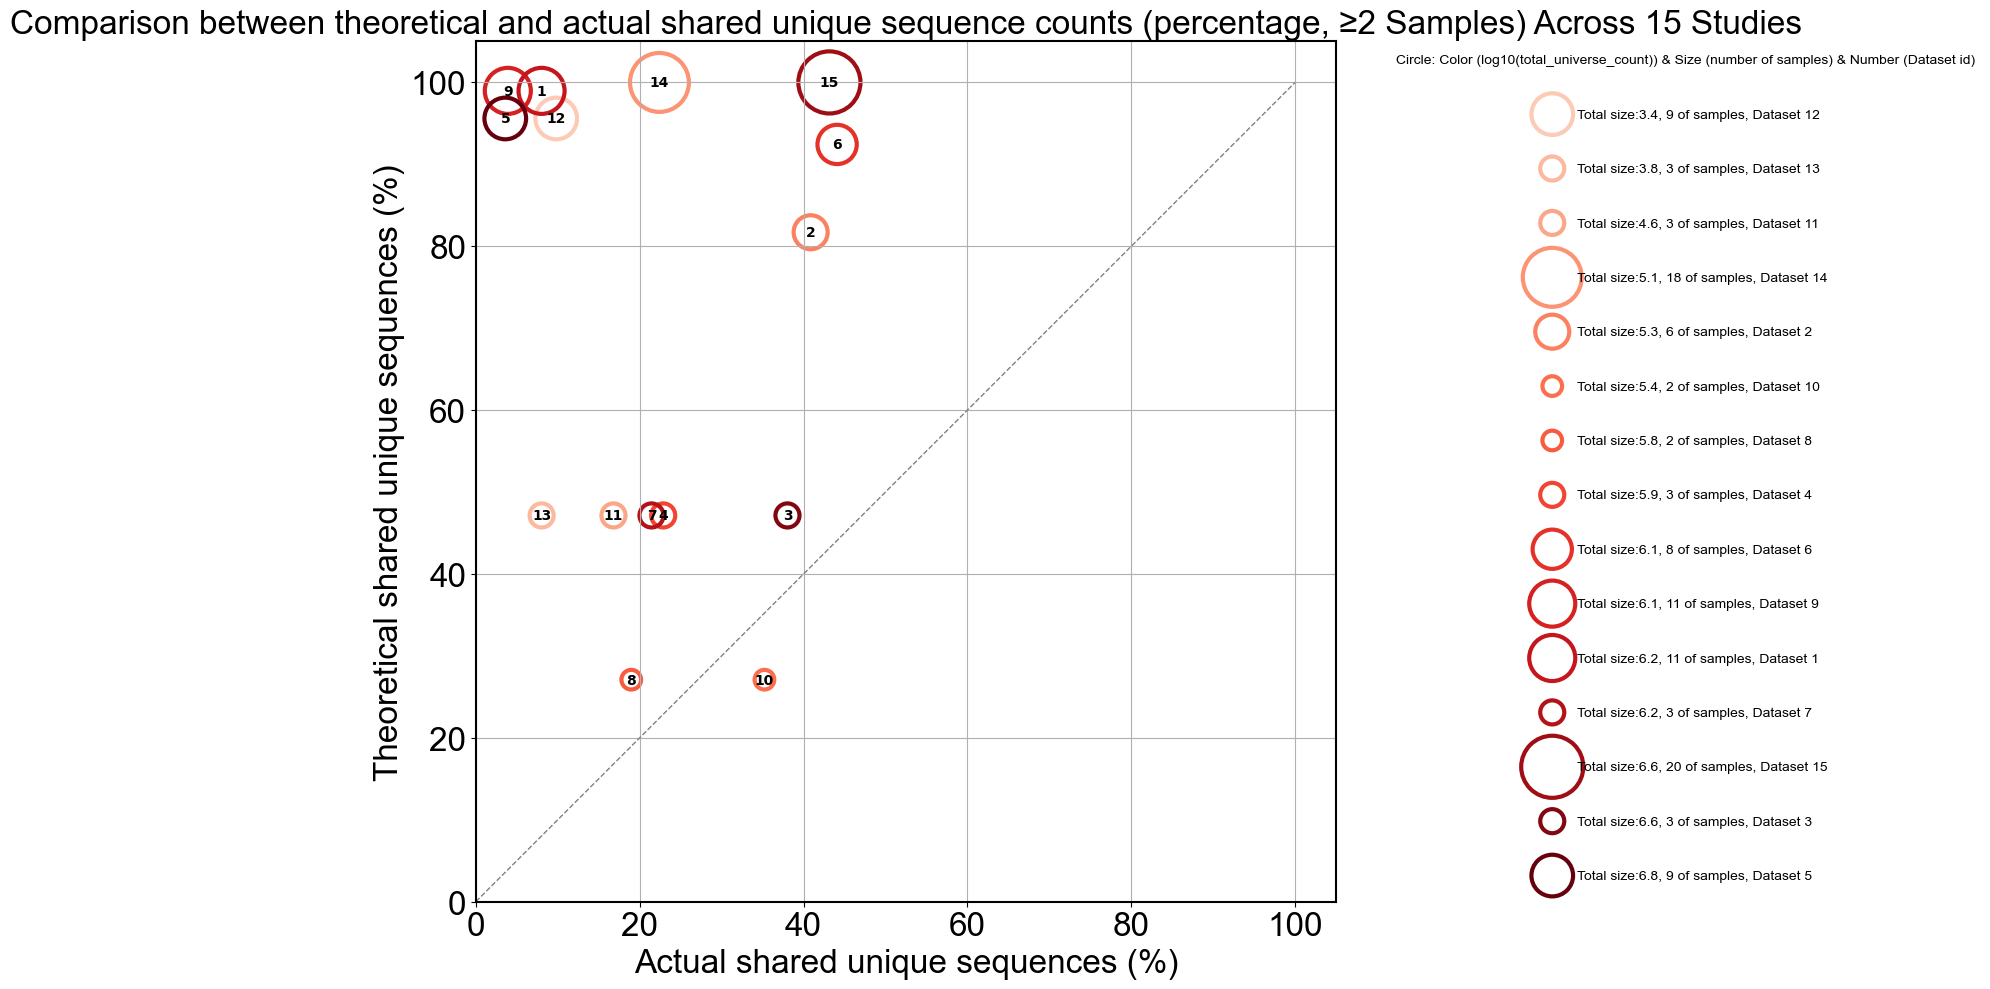

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.patches as mpatches
# from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=24)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=10)
#theory order from 1 sample to 20 samples
# t_temp = [0.0, 0.2, 0.352, 0.4864, 0.59904, 0.6902, 0.7621, 0.8173, 0.8584, 
#                0.8882, 0.9090, 0.9233, 0.9328, 0.9390, 0.9431, 0.9460, 0.9482, 
#                0.9498, 0.9510, 0.9520]
#27.09
t_temp =  [0.0000,
            0.2709,
            0.4714,
            0.6228,
            0.7335,
            0.8171,
            0.8791,
            0.9243,
            0.9560,
            0.9770,
            0.9897,
            0.9963,
            0.9990,
            0.9997,
            0.9999,
            0.99997,
            0.99999,
            0.999995,
            0.999998,
            0.999999]
        
# [0.0000,
#  0.2709,
#  0.4714,
#  0.6228,
#  0.7335,
#  0.8171,
#  0.8791,
#  0.9243,
#  0.9560,
#  0.9770,
#  0.9897,
#  0.9963,
#  0.9990,
#  0.9997,
#  0.9999,
#  0.99997,
#  0.99999,
#  0.999995,
#  0.999998,
#  0.999999]

t = [x * 100 for x in t_temp]
print(t)

df = pd.DataFrame({ "x": [8.01, 40.86, 38.03, 22.86, 3.58, 44.09, 21.43, 18.96, 3.89, 35.22, 16.79, 9.80, 8.02, 22.40, 43.15],
                    "y":  [t[10], t[5], t[2], t[2], t[8], t[7], t[2], t[1], t[10], t[1], t[2], t[8], t[2], t[17], t[19]],
                    "size": [11, 6, 3, 3, 9, 8, 3, 2, 11, 2, 3, 9, 3, 18, 20],
                    'total': [1520705, 186577, 3602055, 748943, 6718413, 1154904, 1759510, 629486, 1392991, 250107, 43804, 2550, 6795, 140193, 3577286],
                    "categorical_variable": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15] })
df_sorted = df.sort_values(by="total")
print(df_sorted)
df_sorted["size_draw"] = (df_sorted["size"]*100).astype(int)
df_sorted["total"] = round((np.log10(df_sorted["total"])),1)
#25.01 + 18.96 + 35.22 /3 = 26 =25%
#0.26 + 0.159 + 0.2/3 = 20%
# df["total_new"] = ((df["total"]/2550)).astype(int)
# df["size_new"] = (df["size"]*10).astype(int)
# df["total_new"] = df["total"] /1000000
# print(np.log10(df["total"]))
# colors = ['#3b4cc0', '#516cc4', '#668cc8', '#7baccc', '#8ec9ce', '#a1e0ce',
#  '#c0e6b2', '#e0db8a', '#f4c264', '#f69b4a', '#ef6f34', '#e24326',
#  '#ca1a1a', '#b40426']
colors = [plt.cm.Reds(i) for i in np.linspace(0.2, 1, 15)] 
# # unique_cats = sorted(df["categorical_variable"].unique())
# colors = [
#     "pink",       # light purple
#     "firebrick",   # tan/orange
#     "orange",      # light blue
#     "green",        # beige
    
#     "rosybrown",    # brownish
#     "purple",

#     "red", # teal green
#     "chocolate",        # orange-pink
#     "deepskyblue",  # strong sky blue
#     "yellowgreen",  # green
#     "gray",       

#     "blue", # pale blue
#     "black",    # bright green
#     "plum"

#     ]
# color_dict = {total: colors[i % len(colors)] for i, total in enumerate(df["categorical_variable"])}
# print(color_dict)

# # size_dict = {int(df["total_new"][i]) : dataset_id for i, dataset_id in enumerate(df["categorical_variable"])}
# # print(size_dict)
# # Map colors to each data point
# df["color"] = df["total"].map(color_dict)


# print(df["color"])

ax = df_sorted.plot.scatter(
    x="x", y="y",
    c="none",
    s="size_draw",
    facecolors='none',
    edgecolors=colors,
    figsize=(15,10),
    linewidths=3,
    grid=True
)
for i, row in df_sorted.iterrows():
    ax.text(
        row["x"], row["y"],               # position
        int(row["categorical_variable"]),                         # text (can be any label, e.g., df['label'])
        color="black",               # optional: same as circle color
        ha='center', va='center',         # center alignment
        fontsize=10, fontweight='bold'
    )
ax.set_aspect('equal', adjustable='box')
# Add 45° line
min_val = min(0, 0)
max_val = max(df["x"].max(), df["y"].max())
ax.plot([min_val, max_val], [min_val, max_val], color="gray", linestyle="--", linewidth=1)
# sizes_sorted = sorted(df["total_new"])
# print(sizes_sorted)
legend_handles = []
for i, (idx, row) in enumerate(df_sorted.iterrows()):
    dataset = row["categorical_variable"].astype(int)
    size = int(row["size"])
    size_new = int(row["size"]) *100
    total = row["total"]
    handle = plt.scatter([], [], 
                            s=size_new, 
                            facecolors='none',
                            linewidths=3,
                            edgecolors=colors[i],
                            label=f"Total size:{total}, {round(size,1)} of samples, Dataset {dataset}")
    legend_handles.append(handle)


ax.legend(
    handles=legend_handles,
    loc='upper left',
    bbox_to_anchor=(1.05, 1),
    title=" Circle: Color (log10(total_universe_count)) & Size (number of samples) & Number (Dataset id)",
    scatterpoints=1,
    frameon=False,
    labelspacing=3,
    prop=arial_font_in,
    title_fontproperties=arial_font_in,
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.5)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.set_title("Comparison between theoretical and actual shared unique sequence counts (percentage, ≥2 Samples) Across 15 Studies", weight="bold",fontproperties=arial_font)
ax.set_xlabel("Actual shared unique sequences (%)", fontproperties=arial_font)
ax.set_ylabel("Theoretical shared unique sequences (%)", fontproperties=arial_font)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontproperties(arial_font)
plt.tight_layout()
plt.show()
# base_path = "/work/yaolab/mzhou10/metaSRNA/release_version/5th_9samples_output"
plt.savefig("figure7_1.pdf", format="pdf", bbox_inches="tight")
plt.close()


          x             y    total  size  categorical_variable
11      250  2.437800e+03     2550     9                    12
12      545  3.203163e+03     6795     3                    13
10     7354  2.064921e+04    43804     3                    11
13    31400  1.401923e+05   140193    18                    14
1     76243  1.524521e+05   186577     6                     2
9     88095  6.775399e+04   250107     2                    10
7    119362  1.705278e+05   629486     2                     8
3    171196  3.530517e+05   748943     3                     4
5    509181  1.067478e+06  1154904     8                     6
8     54181  1.378643e+06  1392991    11                     9
0    121787  1.505042e+06  1520705    11                     1
6    377021  8.294330e+05  1759510     3                     7
14  1543590  3.577282e+06  3577286    20                    15
2   1369797  1.698009e+06  3602055     3                     3
4    240532  6.422803e+06  6718413     9               

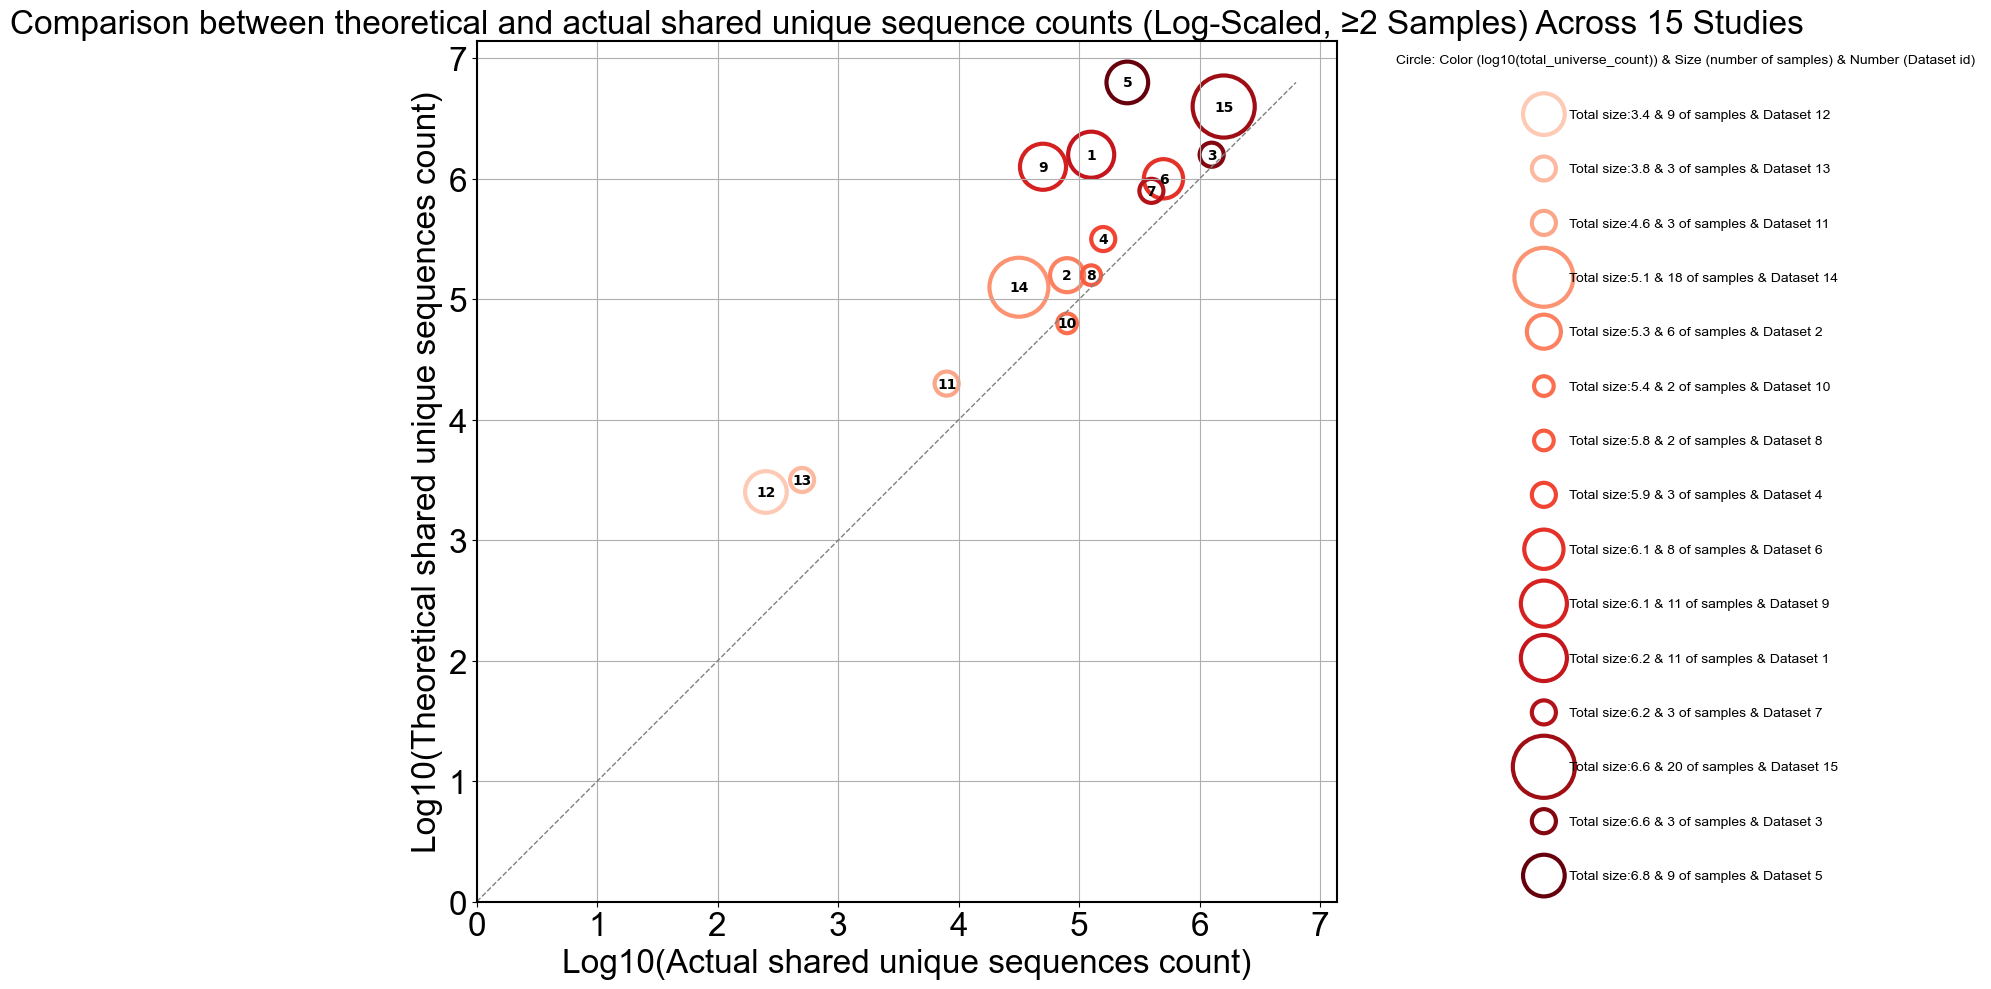

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.patches as mpatches
# from matplotlib_venn import venn2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
import numpy as np
import pandas as pd
import os

fm.fontManager.addfont(str("arial.ttf"))


arial_font = fm.FontProperties(fname="arial.ttf", size=24)
arial_font_in = fm.FontProperties(fname="arial.ttf", size=10)
t_1 = [1520705, 186577, 3602055, 748943, 6718413, 1154904, 1759510, 629486, 1392991, 250107, 43804, 2550, 6795, 140193, 3577286]
# t = [0.0, 0.2, 0.352, 0.4864, 0.59904, 0.6902, 0.7621, 0.8173, 0.8584, 
#         0.8882, 0.9090, 0.9233, 0.9328, 0.9390, 0.9431, 0.9460, 0.9482, 
#         0.9498, 0.9510, 0.9520]
t =        [0.0000,
            0.2709,
            0.4714,
            0.6228,
            0.7335,
            0.8171,
            0.8791,
            0.9243,
            0.9560,
            0.9770,
            0.9897,
            0.9963,
            0.9990,
            0.9997,
            0.9999,
            0.99997,
            0.99999,
            0.999995,
            0.999998,
            0.999999]

df = pd.DataFrame({ 'x': [121787, 76243, 1369797, 171196, 240532, 509181, 377021, 119362, 54181, 88095, 7354, 250, 545, 31400, 1543590], 
                    "y": [t_1[0]*t[10] ,t_1[1]*t[5], t_1[2]*t[2], t_1[3]*t[2], t_1[4]*t[8], t_1[5]*t[7], t_1[6]*t[2], t_1[7]* t[1], t_1[8]* t[10], t_1[9]* t[1], t_1[10]* t[2], t_1[11]* t[8], t_1[12]* t[2],t_1[13]* t[17],t_1[14]* t[19]],
                    'total': [1520705, 186577, 3602055, 748943, 6718413, 1154904, 1759510, 629486, 1392991, 250107, 43804, 2550, 6795, 140193, 3577286],
                    "size": [11, 6, 3, 3, 9, 8, 3, 2, 11, 2, 3, 9, 3, 18, 20],
                    "categorical_variable": [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15] })
df_sorted = df.sort_values(by="total")
print(df_sorted)
df_sorted["size_draw"] = (df_sorted["size"]*100).astype(int)
df_sorted["x"] = round((np.log10(df_sorted["x"])),1)
df_sorted["y"] = round((np.log10(df_sorted["y"])),1)
df_sorted["total"] = round((np.log10(df_sorted["total"])),1)
# df["log_total"] = (np.log10(df["total"]) * 130).astype(int)
# df["x"] = round((np.log10(df["count"])),1)
# df["y"] = round((np.log10(df["theory_count"])),1)
# df["actual_percent"] = round(df["count"]/df["total"],5)
# print(df["actual_percent"].to_list())
# df["log_total"] = df["total"] /1000000
# print(df["log_total"])
# unique_cats = sorted(df["categorical_variable"].unique())
# colors = [
#     "pink",       # light purple
#     "firebrick",   # tan/orange
#     "orange",      # light blue
#     "green",        # beige
    
#     "rosybrown",    # brownish
#     "purple",

#     "red", # teal green
#     "chocolate",        # orange-pink
#     "deepskyblue",  # strong sky blue
#     "yellowgreen",  # green
#     "gray",       

#     "blue", # pale blue
#     "black",    # bright green
#     "plum"

#     ]
# color_dict = {dataset_id: colors[i % len(colors)] for i, dataset_id in enumerate(df["categorical_variable"])}
# print(color_dict)

# size_dict = {int(df["log_total"][i]) : dataset_id for i, dataset_id in enumerate(df["categorical_variable"])}
# print(size_dict)
# # Map colors to each data point
# df["color"] = df["categorical_variable"].map(color_dict)
colors = [plt.cm.Reds(i) for i in np.linspace(0.2, 1, 15)] 

# print(df["color"])

ax = df_sorted.plot.scatter(
    x="x", y="y",
    c="none",
    s="size_draw",
    facecolors='none',
    edgecolors=colors,
    figsize=(15,10),
    linewidths=3,
    grid=True
)
for i, row in df_sorted.iterrows():
    ax.text(
        row["x"], row["y"],               
        int(row["categorical_variable"]),                        
        color="black",               
        ha='center', va='center',         
        fontsize=10, fontweight='bold'
    )
ax.set_aspect('equal', adjustable='box')
# Add 45° line
min_val = min(0, 0)
max_val = max(df_sorted["x"].max(), df_sorted["y"].max())
ax.plot([min_val, max_val], [min_val, max_val], color="gray", linestyle="--", linewidth=1)
# sizes_sorted = sorted(df["log_total"])
# print(sizes_sorted)
legend_handles = []
for i, (idx, row) in enumerate(df_sorted.iterrows()):
    dataset = row["categorical_variable"].astype(int)
    size = int(row["size"])
    size_new = int(row["size"]) *100
    total = row["total"]
    handle = plt.scatter([], [], 
                            s=size_new, 
                            facecolors='none',
                            linewidths=3,
                            edgecolors=colors[i],
                            label=f"Total size:{total} & {round(size,1)} of samples & Dataset {dataset}")
    legend_handles.append(handle)


ax.legend(
    handles=legend_handles,
    loc='upper left',
    bbox_to_anchor=(1.05, 1),
    title=" Circle: Color (log10(total_universe_count)) & Size (number of samples) & Number (Dataset id)",
    scatterpoints=1,
    frameon=False,
    labelspacing=3,
    prop=arial_font_in,
    title_fontproperties=arial_font_in,
)

for spine in ax.spines.values():
    spine.set_visible(True)
    spine.set_color("black")
    spine.set_linewidth(1.5)
ax.set_xlim(left=0)
ax.set_ylim(bottom=0)

ax.set_title("Comparison between theoretical and actual shared unique sequence counts (Log-Scaled, ≥2 Samples) Across 15 Studies", weight="bold",fontproperties=arial_font)
ax.set_xlabel("Log10(Actual shared unique sequences count)", fontproperties=arial_font)
ax.set_ylabel("Log10(Theoretical shared unique sequences count)", fontproperties=arial_font)

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontproperties(arial_font)
plt.tight_layout()
plt.show()
# base_path = "/work/yaolab/mzhou10/metaSRNA/release_version/5th_9samples_output"
plt.savefig("figure7_2.pdf", format="pdf", bbox_inches="tight")
plt.close()
